Brayden Yow  
09/12/2026  
Lab 2 - Energy-Tracking Projectile

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [1]:
def simulate_projectile_2d(v0, theta_deg, dt, g=9.81):
    theta = np.radians(theta_deg)
    vx = v0 * np.cos(theta)
    vy = v0 * np.sin(theta)
    # inital position and time
    x = 0.0
    y = 0.0
    t = 0.0
    m = 1.0 # mass of object
    # calcualte the endergies 
    KE = 0.5 * m * (vx**2 + vy**2) # Kinetic energy
    PE = m * g * y # potential energy 
    E_total = KE + PE # total energy 
    # arrays to store results
    t_arr = [t]
    x_arr = [x]
    y_arr = [y]
    vx_arr = [vx]
    vy_arr = [vy]
    KE_list = [KE] # kinetic energy 
    PE_list = [PE] # potential energy
    E_total_list = [E_total]   # total energy 
    while y >= 0.0:
        ax = 0.0
        ay = -g
        # Euler method updates for 2D
        x += vx * dt
        y += vy * dt
        vx += ax * dt
        vy += ay * dt
        t += dt
        # Calculate energies again 
        KE = 0.5 * m * (vx**2 + vy**2) # Kinetic energy
        PE = m * g * y # potential energy 
        E_total = KE + PE # total energy      
        # Append data
        t_arr.append(t)
        x_arr.append(x)
        y_arr.append(y)
        vx_arr.append(vx)
        vy_arr.append(vy)
        KE_list.append(KE)
        PE_list.append(PE)
        E_total_list.append(E_total)
    return t_arr, x_arr, y_arr, vx_arr, vy_arr, KE_list, PE_list, E_total_list


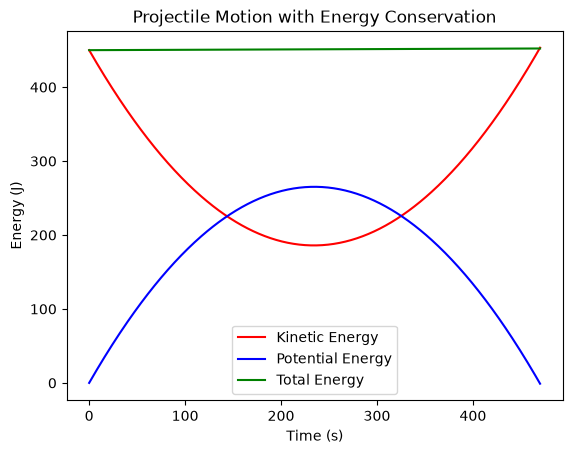

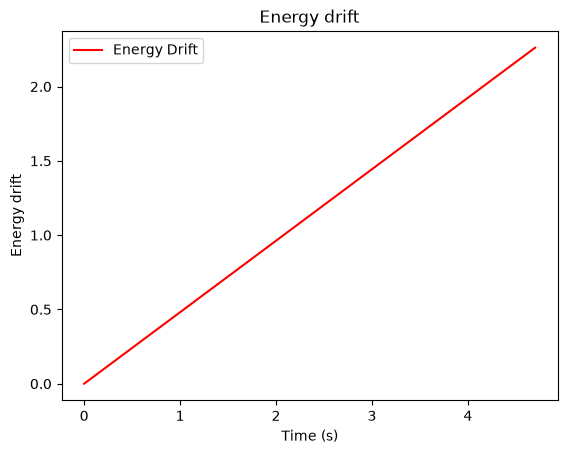

In [3]:
t_arr, x_arr, y_arr, vx_arr, vy_arr, KE_list, PE_list, E_total_list = simulate_projectile_2d(v0=30, theta_deg = 50, dt = 0.01)
plt.title("Projectile Motion with Energy Conservation")
plt.xlabel("Time (s)")
plt.ylabel("Energy (J)")
plt.plot(KE_list, "r-", label = "Kinetic Energy",)
plt.plot(PE_list, "b-", label = "Potential Energy")
plt.plot(E_total_list, "g-", label = "Total Energy")
plt.legend()
plt.show()
plt.plot(t_arr, E_total_list-E_total_list[0], "r-", label = "Energy Drift")
plt.title("Energy drift")
plt.xlabel("Time (s)")
plt.ylabel("Energy drift")
plt.legend()
plt.show()

In [4]:
t_arr, x_arr, y_arr, vx_arr, vy_arr, KE_list, PE_list, E_total_list = simulate_projectile_2d(v0=30, theta_deg = 50, dt = 0.01)

energy_drift = E_total_list - E_total_list[0]
max_energy_drift = np.max(energy_drift)
E0 = E_total_list[0]
Percent_drift = (max_energy_drift / E0) * 100
print(Percent_drift)
print(max_energy_drift)

0.5025662999999744
2.2615483499998845


Report the maximum absolute energy drift over the flight, and express it as a percentage of the initial energy.
The maximum absolute energy drift for the flight was 2.3% while the total drift from the inital energy was 0.50%

 Interpret it: 
 The drift in the value of energy based off of the graph created seems to grow at a steady rate the is linear. By adjusting the values of dt I can see that the relationship of how much error is accumulated is directly related to the time steps. If you increase the value of dt by 10x the error accumulated increases by the same factor. 



Part B — Euler vs. Euler-Cromer

In [5]:
def simulate_projectile(method,v0, theta_deg, dt, g=9.81):



    theta = np.radians(theta_deg)
    vx = v0 * np.cos(theta)
    vy = v0 * np.sin(theta)
    # inital position and time
    x = 0.0
    y = 0.0
    t = 0.0
    m = 1.0 # mass of object
    # calcualte the endergies 
    KE = 0.5 * m * (vx**2 + vy**2) # Kinetic energy
    PE = m * g * y # potential energy 
    E_total = KE + PE # total energy 
    # arrays to store results
    t_arr = [t]
    x_arr = [x]
    y_arr = [y]
    vx_arr = [vx]
    vy_arr = [vy]
    KE_list = [KE] # kinetic energy 
    PE_list = [PE] # potential energy
    E_total_list = [E_total]   # total energy 
    while y >= 0.0:
        ax = 0.0
        ay = -g

        if method == 'euler':
            x  += vx * dt        # position uses OLD velocity
            y  += vy * dt
            vx += ax * dt
            vy += ay * dt
        elif method == 'euler-cromer':
            vx += ax * dt        # velocity updated FIRST
            vy += ay * dt
            x  += vx * dt        # position uses NEW velocity
            y  += vy * dt


        t += dt
        # Calculate energies again 
        KE = 0.5 * m * (vx**2 + vy**2) # Kinetic energy
        PE = m * g * y # potential energy 
        E_total = KE + PE # total energy      
        # Append data
        t_arr.append(t)
        x_arr.append(x)
        y_arr.append(y)
        vx_arr.append(vx)
        vy_arr.append(vy)
        KE_list.append(KE)
        PE_list.append(PE)
        E_total_list.append(E_total)
    return t_arr, x_arr, y_arr, vx_arr, vy_arr, KE_list, PE_list, E_total_list


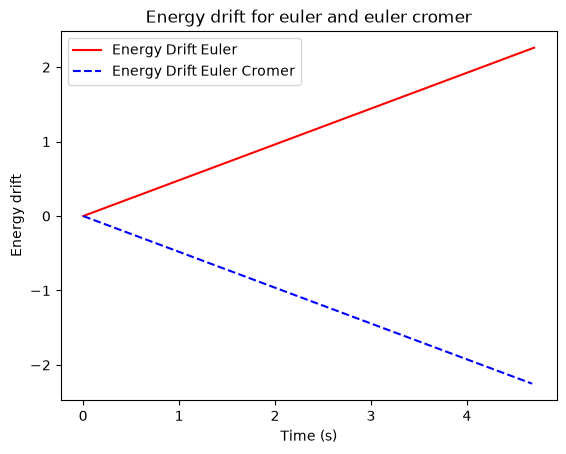

In [6]:
t_arr, x_arr, y_arr, vx_arr, vy_arr, KE_list, PE_list, E_total_list = simulate_projectile("euler",v0=30, theta_deg = 50, dt = 0.01)
t_arr_c, x_arr_c, y_arr_c, vx_arr_c, vy_arr_c, KE_list_c, PE_list_c, E_total_list_c = simulate_projectile("euler-cromer",v0=30, theta_deg = 50, dt = 0.01)

plt.plot(t_arr, E_total_list-E_total_list[0], "r-", label = "Energy Drift Euler")
plt.plot(t_arr_c, E_total_list_c-E_total_list_c[0], "b--", label = "Energy Drift Euler Cromer")
plt.title("Energy drift for euler and euler cromer")
plt.xlabel("Time (s)")
plt.ylabel("Energy drift")
plt.legend()
plt.show()

Compare the trajectories: plot y vs. x for both methods on the same axes. Are they visibly different? Report the difference in landing range between the two methods. 
The Cromer method seems to just have the opposite magnitude of the non cromer method. From the information given in lesson 2 I know this is because for a projectile the force doesn’t depend on the position and therefore the velocity is exact in both methods. 

Explain it: 
In the standard Euler method, it assumes that the velocity and acceleration is constant over the time steps that it takes. This means when it doses its calculation it takes values that don’t match the true model causing an over shooting in the values. In the Euler Cromer method, it updates the velocity first and the finds the position with this data. This has its won problem in motion as it tends to underestimate the values. This key difference is when it comes to oscillating where the force is dependent on position. If you calculate the position before the velocity, it will drastically increase error in oscillating frames. 

Part C — Convergence Study

In [7]:
def simulate_projectile(method,v0, theta_deg, dt, g=9.81):



    theta = np.radians(theta_deg)
    vx = v0 * np.cos(theta)
    vy = v0 * np.sin(theta)
    # inital position and time
    x = 0.0
    y = 0.0
    t = 0.0
    m = 1.0 # mass of object
    # calcualte the endergies 
    KE = 0.5 * m * (vx**2 + vy**2) # Kinetic energy
    PE = m * g * y # potential energy 
    E_total = KE + PE # total energy 
    # arrays to store results
    t_arr = [t]
    x_arr = [x]
    y_arr = [y]
    vx_arr = [vx]
    vy_arr = [vy]
    KE_list = [KE] # kinetic energy 
    PE_list = [PE] # potential energy
    E_total_list = [E_total]   # total energy 
    while y >= 0.0:
        ax = 0.0
        ay = -g

        if method == 'euler':
            x  += vx * dt        # position uses OLD velocity
            y  += vy * dt
            vx += ax * dt
            vy += ay * dt
        elif method == 'euler-cromer':
            vx += ax * dt        # velocity updated FIRST
            vy += ay * dt
            x  += vx * dt        # position uses NEW velocity
            y  += vy * dt


        t += dt
        # Calculate energies again 
        KE = 0.5 * m * (vx**2 + vy**2) # Kinetic energy
        PE = m * g * y # potential energy 
        E_total = KE + PE # total energy      
        # Append data
        t_arr.append(t)
        x_arr.append(x)
        y_arr.append(y)
        vx_arr.append(vx)
        vy_arr.append(vy)
        KE_list.append(KE)
        PE_list.append(PE)
        E_total_list.append(E_total)
    return t_arr, x_arr, y_arr, vx_arr, vy_arr, KE_list, PE_list, E_total_list

Standard Euler Measured Order p = 1.01
Euler-Cromer Measured Order p = 0.99


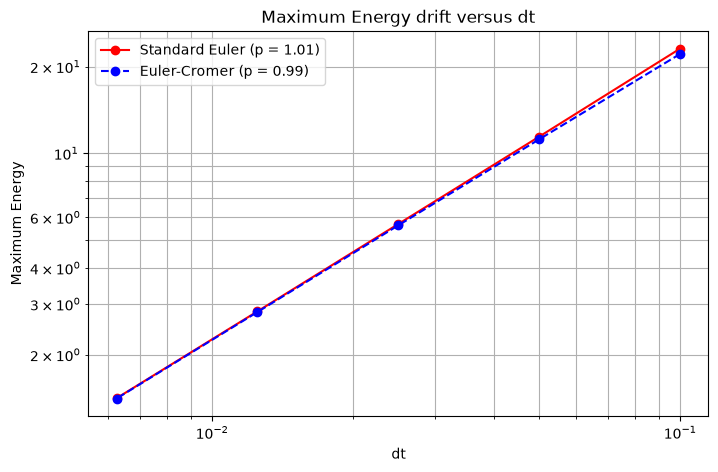

In [8]:
dt_s = [ 0.1,0.05, 0.025, 0.0125, 0.00625]
euler_drift = []
euler_croma_drift = []
for dt in dt_s:
   #euler
   vals_e = simulate_projectile("euler",v0=30, theta_deg = 50, dt=dt)
   Euler_en_e = vals_e[-1]
   max_drift_e = max(abs(Euler_en_e - Euler_en_e[0]))
   euler_drift.append(max_drift_e)

   #euler croma 
   vals_ec = simulate_projectile("euler-cromer", v0=30, theta_deg = 50, dt=dt)
   Euler_croma_ec = vals_ec [-1]
   max_drift_ec = max(abs(Euler_croma_ec - Euler_croma_ec[0]))
   euler_croma_drift.append(max_drift_ec)


p_euler = np.polyfit(np.log(dt_s), np.log(euler_drift), 1)[0]
p_cromer = np.polyfit(np.log(dt_s), np.log(euler_croma_drift), 1)[0]

print(f"Standard Euler Measured Order p = {p_euler:.2f}")
print(f"Euler-Cromer Measured Order p = {p_cromer:.2f}")

plt.figure(figsize=(8, 5))
plt.loglog(dt_s, euler_drift, "ro-", label = f"Standard Euler (p = {p_euler:.2f})")
plt.loglog(dt_s, euler_croma_drift,  "bo--", label = f"Euler-Cromer (p = {p_cromer:.2f})")
plt.title("Maximum Energy drift versus dt")
plt.ylabel("Maximum Energy")
plt.xlabel("dt")

plt.grid(True, which="both")
plt.legend()
plt.show()



Analyze it:
What is the measured order p of standard Euler for energy drift? Does it match what the Week 2 lesson predicted?
The measured order of p of the standard Euler for energy drift was 1.01. Week twos lesion predicted that it should be a first order. This is know from experimentally changing the dt directly changed the error by the same factor.

How does Euler-Cromer's convergence curve compare? Is its energy drift smaller at every step size you tested?
The order of the Euler Cromer’s convergence curve is also near 1 at 0.99. looking closely it is consistently under the values for the Euler drift.

If you needed the energy conserved to within 0.01%, which method and roughly what step size would you choose? Justify with your data.
For a problem that only has gravity acting on it the two methods are equal in their validity, however, it is generally better if the Euler Cromer method is used as it is consistently more accurate. Due to the slope of 1 we know that dt is directly proportional to our error.  With our initial energy (1/2 mv^2) being 450J and an acceptable error of 0.01% gives a margin of 0.0450J. given that at a dt of 0.01 the error is 2.26J we can us some algebra to find that we need a dt that is 50 times smaller. Giving a dt of 0.0002.